In [21]:
import os
import urllib.request
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import (
    OLSInfluence,
    variance_inflation_factor,
)

In [12]:
url = "http://aire.cdmx.gob.mx/descargas/Opendata/anuales_horarios/contaminantes_2026.csv"
filename = "contaminantes_2026.csv"

if not os.path.exists(filename):
    print(f"Descargando {filename} desde el portal del SIMAT...")
    urllib.request.urlretrieve(url, filename)
    print("Descarga finalizada con éxito.")
else:
    print(f"El archivo '{filename}' ya existe en el entorno local.")

El archivo 'contaminantes_2026.csv' ya existe en el entorno local.


In [13]:
df = pd.read_csv(filename, skiprows=9)

In [24]:
# a) Tabla con un renglón por estación-hora y una columna por contaminante
tabla_estacion_hora = df.pivot(
    index=["id_station", "date"], columns="id_parameter", values="valor"
).reset_index()

print("a) TABLA CON UN RENGLÓN POR ESTACIÓN-HORA Y COLUMNAS POR CONTAMINANTE:")
print(f"Dimensiones de la tabla pivotada: {tabla_estacion_hora.shape}")
tabla_estacion_hora.head()

a) TABLA CON UN RENGLÓN POR ESTACIÓN-HORA Y COLUMNAS POR CONTAMINANTE:
Dimensiones de la tabla pivotada: (172992, 11)


id_parameter,id_station,date,CO,NO,NO2,NOX,O3,PM10,PM2.5,PMCO,SO2
0,ACO,2026-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ACO,2026-01-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ACO,2026-01-01 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ACO,2026-01-01 03:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ACO,2026-01-01 04:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [25]:
contaminantes = [
    "CO",
    "NO",
    "NO2",
    "NOX",
    "O3",
    "PM10",
    "PM2.5",
    "PMCO",
    "SO2",
]

# 1. Con faltantes (eliminación por parejas / Pairwise correlation)
corr_con_na = tabla_estacion_hora[contaminantes].corr(method="pearson")
eig_con_na = np.linalg.eigvals(corr_con_na)

# 2. Sin faltantes (casos completos / Complete cases)
tabla_limpia = tabla_estacion_hora[contaminantes].dropna()
corr_sin_na = tabla_limpia.corr()
eig_sin_na = np.linalg.eigvals(corr_sin_na)

print("==================================================")
print("c) EIGENVALORES DE LA MATRIZ DE CORRELACIÓN")
print("==================================================")
print("Eigenvalores (calculados con datos faltantes - Pairwise):")
print(np.sort(eig_con_na)[::-1])

print("\nEigenvalores (calculados sin datos faltantes - Complete Cases):")
print(np.sort(eig_sin_na)[::-1])

c) EIGENVALORES DE LA MATRIZ DE CORRELACIÓN
Eigenvalores (calculados con datos faltantes - Pairwise):
[ 4.30334433e+00  1.99286324e+00  9.18607074e-01  6.57686418e-01
  5.58406495e-01  4.28956904e-01  1.43673157e-01  7.40368316e-05
 -3.61164851e-03]

Eigenvalores (calculados sin datos faltantes - Complete Cases):
[4.45566736e+00 1.97826856e+00 9.12215561e-01 6.44520919e-01
 5.52580044e-01 3.34202907e-01 1.22035593e-01 3.77960257e-04
 1.31095637e-04]


In [26]:
contaminantes = [
    "CO",
    "NO",
    "NO2",
    "NOX",
    "O3",
    "PM10",
    "PM2.5",
    "PMCO",
    "SO2",
]

# 1. Con faltantes (eliminación por parejas / Pairwise correlation)
corr_con_na = tabla_estacion_hora[contaminantes].corr(method="pearson")
eig_con_na = np.linalg.eigvals(corr_con_na)

# 2. Sin faltantes (casos completos / Complete cases)
tabla_limpia = tabla_estacion_hora[contaminantes].dropna()
corr_sin_na = tabla_limpia.corr()
eig_sin_na = np.linalg.eigvals(corr_sin_na)

print("==================================================")
print("c) EIGENVALORES DE LA MATRIZ DE CORRELACIÓN")
print("==================================================")
print("Eigenvalores (calculados con datos faltantes - Pairwise):")
print(np.sort(eig_con_na)[::-1])

print("\nEigenvalores (calculados sin datos faltantes - Complete Cases):")
print(np.sort(eig_sin_na)[::-1])

c) EIGENVALORES DE LA MATRIZ DE CORRELACIÓN
Eigenvalores (calculados con datos faltantes - Pairwise):
[ 4.30334433e+00  1.99286324e+00  9.18607074e-01  6.57686418e-01
  5.58406495e-01  4.28956904e-01  1.43673157e-01  7.40368316e-05
 -3.61164851e-03]

Eigenvalores (calculados sin datos faltantes - Complete Cases):
[4.45566736e+00 1.97826856e+00 9.12215561e-01 6.44520919e-01
 5.52580044e-01 3.34202907e-01 1.22035593e-01 3.77960257e-04
 1.31095637e-04]


In [27]:
# Preparación de datos para regresiones (Casos completos)
y = tabla_limpia["PM2.5"]

# 1. Modelo con TODOS los demás contaminantes
X_todos = sm.add_constant(tabla_limpia.drop(columns=["PM2.5"]))
modelo_todos = sm.OLS(y, X_todos).fit()

# 2. Modelo SOLO con gases ('CO', 'NO', 'NO2', 'NOX', 'O3', 'SO2')
gases = ["CO", "NO", "NO2", "NOX", "O3", "SO2"]
X_gases = sm.add_constant(tabla_limpia[gases])
modelo_gases = sm.OLS(y, X_gases).fit()

print("==================================================")
print("d) MODELOS DE PREDICCIÓN PARA PM2.5")
print("==================================================")
print(f"R² Modelo Todos los contaminantes: {modelo_todos.rsquared:.4f}")
print(f"R² Modelo Solo Gases:              {modelo_gases.rsquared:.4f}\n")

# VIF para el modelo completo
vif_todos = pd.DataFrame()
vif_todos["Variable"] = X_todos.columns
vif_todos["VIF"] = [
    variance_inflation_factor(X_todos.values, i)
    for i in range(X_todos.shape[1])
]

print("VIF - Modelo con Todos los Contaminantes:")
print(vif_todos.to_string(index=False))

d) MODELOS DE PREDICCIÓN PARA PM2.5
R² Modelo Todos los contaminantes: 0.9983
R² Modelo Solo Gases:              0.4055

VIF - Modelo con Todos los Contaminantes:
Variable         VIF
   const    1.000000
      CO    5.710228
      NO 2324.236785
     NO2  780.733295
     NOX 4528.146814
      O3    1.773441
    PM10    4.543673
    PMCO    3.403099
     SO2    1.109554


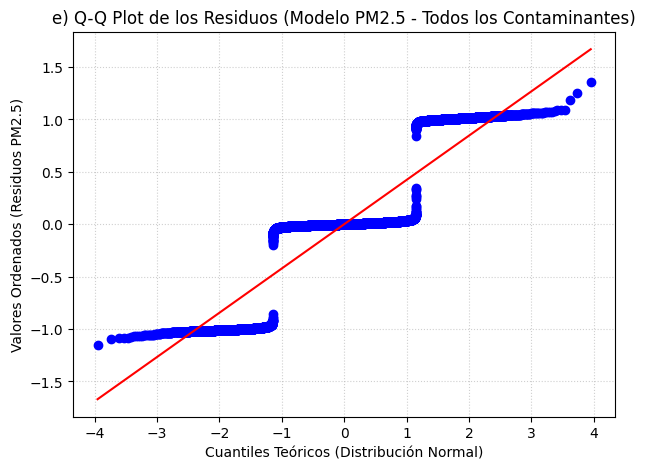

In [30]:
# 1. Extraer los residuos del modelo completo de PM2.5
residuos_pm25 = modelo_todos.resid

# 2. Generar el Q-Q Plot
plt.figure(figsize=(7, 5))
stats.probplot(residuos_pm25, dist="norm", plot=plt)
plt.title(
    "e) Q-Q Plot de los Residuos (Modelo PM2.5 - Todos los Contaminantes)"
)
plt.xlabel("Cuantiles Teóricos (Distribución Normal)")
plt.ylabel("Valores Ordenados (Residuos PM2.5)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

In [29]:
# f) Cálculo de Distancia de Cook y Leverage (Hat values)
influencia = OLSInfluence(modelo_todos)
cooks_d = influencia.cooks_distance[0]
leverage = influencia.hat_matrix_diag

df_diag = pd.DataFrame(
    {"cooks_d": cooks_d, "leverage": leverage}, index=tabla_limpia.index
)

# Obtener los 10 índices más influyentes de cada métrica
top_10_cook = df_diag.sort_values(by="cooks_d", ascending=False).head(10)
top_10_leverage = df_diag.sort_values(by="leverage", ascending=False).head(10)

coincidencias = set(top_10_cook.index).intersection(set(top_10_leverage.index))

print("==================================================")
print("f) ANÁLISIS DE COOK vs LEVERAGE")
print("==================================================")
print(f"Top 10 observaciones por Distancia de Cook:\n{list(top_10_cook.index)}")
print(
    f"\nTop 10 observaciones por Leverage (Apalancamiento):\n{list(top_10_leverage.index)}"
)
print(
    f"\n¿Los 10 más influyentes (Cook) son los de más leverage? Coinciden {len(coincidencias)} de las 10 observaciones."
)

# Reajuste eliminando los 10 puntos con mayor distancia de Cook
tabla_sin_cook = tabla_limpia.drop(index=top_10_cook.index)
X_reajuste = sm.add_constant(tabla_sin_cook.drop(columns=["PM2.5"]))
y_reajuste = tabla_sin_cook["PM2.5"]

modelo_reajustado = sm.OLS(y_reajuste, X_reajuste).fit()

print("\n--------------------------------------------------")
print(
    f"R² Original:   {modelo_todos.rsquared:.6f}"
)
print(
    f"R² Reajustado: {modelo_reajustado.rsquared:.6f}"
)
print("--------------------------------------------------")

f) ANÁLISIS DE COOK vs LEVERAGE
Top 10 observaciones por Distancia de Cook:
[157735, 92743, 157731, 158719, 146567, 157730, 92791, 25542, 158239, 25543]

Top 10 observaciones por Leverage (Apalancamiento):
[157735, 92743, 157734, 157737, 157736, 142753, 157738, 157733, 157739, 92595]

¿Los 10 más influyentes (Cook) son los de más leverage? Coinciden 2 de las 10 observaciones.

--------------------------------------------------
R² Original:   0.998310
R² Reajustado: 0.998268
--------------------------------------------------
